In [1]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [2]:
df = pd.read_csv("diabetes_patients_10000_full.csv")
df.head()

,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1.0,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2.0,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3.0,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4.0,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5.0,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [3]:
df.drop("Patient_ID" , inplace = True , axis = 1)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                9675 non-null   float64
 1   Gender             9530 non-null   object 
 2   Blood_Sugar_Level  9535 non-null   float64
 3   Creatinine         9749 non-null   float64
 4   BMI                9749 non-null   float64
 5   Urea               9740 non-null   float64
 6   Cholesterol        9937 non-null   float64
 7   HbA1c              9986 non-null   float64
 8   Class              9985 non-null   object 
dtypes: float64(7), object(2)
memory usage: 703.3+ KB


In [5]:
df.describe()

,Age,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c
count,9675.000000,9535.000000,9749.000000,9749.000000,9740.000000,9937.000000,9986.000000
mean,49.971266,169.185632,1.100609,26.746805,35.126591,225.351112,7.503875
std,17.627406,46.055875,0.287080,4.787478,11.818323,43.796330,1.743940
min,20.000000,90.000000,0.600000,18.500000,15.000000,150.000000,4.500000
25%,35.000000,130.000000,0.850000,22.600000,25.000000,187.000000,6.000000
50%,50.000000,169.000000,1.100000,26.700000,35.000000,225.000000,7.500000
75%,65.000000,209.000000,1.350000,31.000000,45.000000,263.000000,9.000000
max,80.000000,250.000000,1.600000,35.000000,55.000000,300.000000,10.500000


In [6]:
df.isna().sum()

Age                  325
Gender               470
Blood_Sugar_Level    465
Creatinine           251
BMI                  251
Urea                 260
Cholesterol           63
HbA1c                 14
Class                 15
dtype: int64

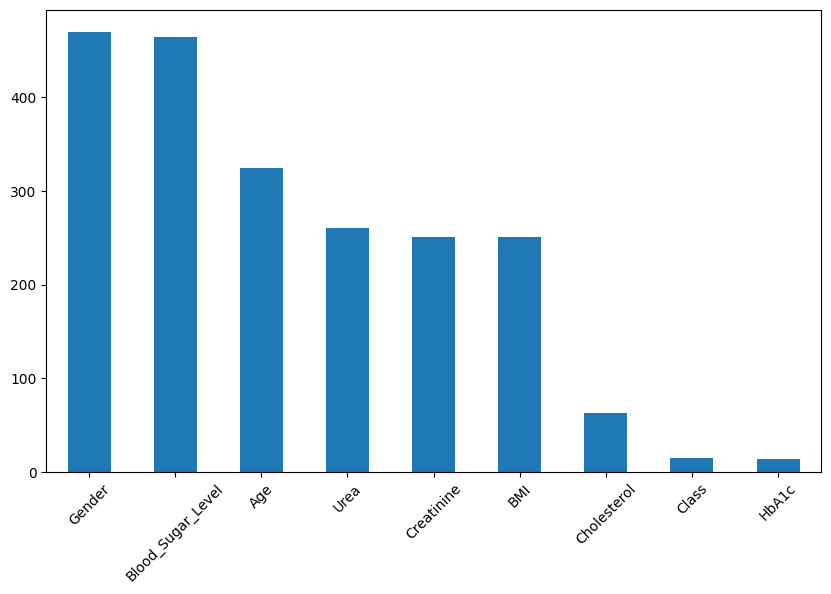

In [7]:
plt.figure(figsize=(10,6))
df.isna().sum().sort_values(ascending = False).plot(kind = 'bar')
plt.xticks(rotation = 45)
plt.show()

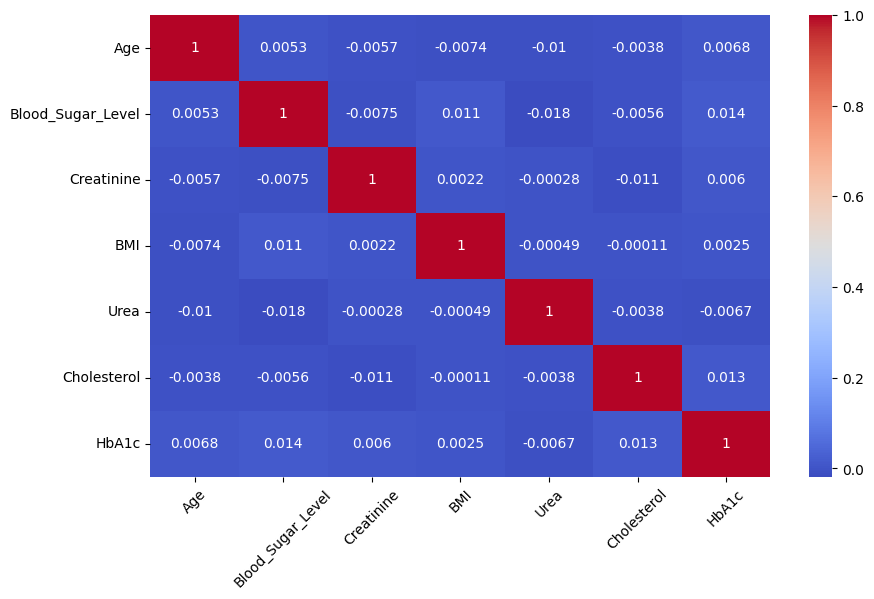

In [8]:
plt.figure(figsize = (10 ,6))
sns.heatmap(df.corr(numeric_only= True) ,annot = True ,cmap = 'coolwarm')
plt.xticks(rotation = 45)
plt.show()

In [9]:
ohe = ["Gender"]
scale = ["Age" ,  "Blood_Sugar_Level","Creatinine", "BMI", "Urea" , "Cholesterol", "HbA1c"]

In [10]:
numerical_pipline = Pipeline( steps = [
    ("imputer", SimpleImputer(strategy= "median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(
    steps = [

             ('imputer', SimpleImputer(strategy= "most_frequent")),
             ("encoder", OneHotEncoder(sparse_output=False , handle_unknown = "ignore"))
    ]
)

In [11]:
  preprocessor = ColumnTransformer(
      transformers = [
          ("num", numerical_pipline , scale),
          ("cat", categorical_pipeline , ohe)
      ],
          remainder="drop"

  )

In [12]:
X = df.drop('Class' , axis = 1)
y = df['Class']

In [13]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=.2 , random_state=1234)

In [14]:
X_train.shape

(8000, 8)

In [15]:
from sklearn.tree import DecisionTreeClassifier

In [16]:
pipline = Pipeline(steps = [
    ("preprocessor" , preprocessor),
    ("model" , DecisionTreeClassifier(random_state=42, class_weight="balanced"))
])

In [17]:
pipline.fit(X_train, y_train)

ValueError: Input contains NaN

In [ ]:
pipline.score(X_train, y_train)

1.0

In [ ]:
y_pred = pipline.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9994979919678715
              precision    recall  f1-score   support

    Diabetic       1.00      1.00      1.00      1820
Non-Diabetic       1.00      0.99      1.00       172

    accuracy                           1.00      1992
   macro avg       1.00      1.00      1.00      1992
weighted avg       1.00      1.00      1.00      1992

[[1820    0]
 [   1  171]]


In [ ]:
import pickle

# Train pipeline
pipline.fit(X_train, y_train)

# Save as Pickle
with open("diabetes_pipeline.pkl", "wb") as file:
    pickle.dump(pipline, file)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
with open("diabetes_pipeline.pkl", "rb") as file:
    loaded_model = pickle.load(file)

In [ ]:
y_pred = loaded_model.predict(X_test)

In [ ]:
import streamlit as st
import pandas as pd
import pickle
from pathlib import Path

# =========================
# Page Configuration
# =========================
st.set_page_config(
    page_title="Diabetes Prediction",
    page_icon="🩺",
    layout="wide"
)

# =========================
# Load Model
# =========================
@st.cache_resource
def load_model():
    with open("diabetes_pipeline.pkl", "rb") as file:
        return pickle.load(file)

try:
    model = load_model()
except FileNotFoundError:
    st.error("diabetes_pipeline.pkl not found!")
    st.stop()

# =========================
# Header
# =========================
st.title("🩺 Diabetes Prediction System")
st.markdown(
    "### Machine Learning Classification"
)
st.divider()

st.info(
    "Enter patient information to get a model prediction."
)

# =========================
# Patient Information
# =========================
st.subheader("Patient Information")

col1, col2 = st.columns(2)

with col1:
    age = st.number_input(
        "Age",
        min_value=1,
        max_value=120,
        value=30
    )

    gender = st.selectbox(
        "Gender",
        ["Male", "Female"]
    )

    blood_sugar = st.number_input(
        "Blood Sugar Level",
        min_value=0.0,
        value=100.0
    )

    creatinine = st.number_input(
        "Creatinine",
        min_value=0.0,
        value=1.0
    )

with col2:
    bmi = st.number_input(
        "BMI",
        min_value=0.0,
        value=25.0
    )

    urea = st.number_input(
        "Urea",
        min_value=0.0,
        value=30.0
    )

    cholesterol = st.number_input(
        "Cholesterol",
        min_value=0.0,
        value=180.0
    )

    hba1c = st.number_input(
        "HbA1c",
        min_value=0.0,
        value=5.5
    )

st.divider()

# =========================
# Prediction
# =========================
if st.button("🔍 Predict Diabetes Class", use_container_width=True):

    input_data = pd.DataFrame([{
        "Age": age,
        "Gender": gender,
        "Blood_Sugar_Level": blood_sugar,
        "Creatinine": creatinine,
        "BMI": bmi,
        "Urea": urea,
        "Cholesterol": cholesterol,
        "HbA1c": hba1c
    }])

    try:
        prediction = model.predict(input_data)[0]

        st.subheader("Prediction Result")

        st.success(f"Predicted Class: {prediction}")

        # Prediction probabilities
        if hasattr(model, "predict_proba"):

            probabilities = model.predict_proba(input_data)[0]

            probability_df = pd.DataFrame({
                "Class": model.classes_.astype(str),
                "Probability": probabilities
            })

            st.subheader("Prediction Probabilities")

            st.bar_chart(
                probability_df.set_index("Class")
            )

            st.dataframe(
                probability_df.style.format(
                    {"Probability": "{:.2%}"}
                ),
                use_container_width=True
            )

    except Exception as e:
        st.error(f"Prediction Error: {e}")

# =========================
# Footer
# =========================
st.divider()

st.caption(
    "Diabetes Prediction | Machine Learning Project"
)

st.warning(
    "Educational demonstration only. "
    "This application is not a medical diagnostic tool."
)

2026-10-31 16:07:29.503 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.505 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.506 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.507 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.509 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.510 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.511 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-31 16:07:29.512 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

## Model Comparison


In [ ]:
_Xtr = globals().get("X_train_scaled", X_train)
_Xte = globals().get("X_test_scaled", X_test)

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []
for name, m in models.items():
    m.fit(_Xtr, y_train)
    p = m.predict(_Xte)
    results.append({"Model": name,
                    "Train Accuracy": accuracy_score(y_train, m.predict(_Xtr)),
                    "Test Accuracy": accuracy_score(y_test, p),
                    "Precision": precision_score(y_test, p, average="weighted", zero_division=0),
                    "Recall": recall_score(y_test, p, average="weighted", zero_division=0),
                    "F1": f1_score(y_test, p, average="weighted", zero_division=0)})

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df